In [1]:
import os
import time

import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import MDS, TSNE, Isomap, LocallyLinearEmbedding, SpectralEmbedding
from sklearn.preprocessing import StandardScaler
from umap import UMAP

# The course's automatic tests set COURSE_SMOKE=1: 500 digits instead of all 1,797
SMOKE = os.environ.get("COURSE_SMOKE") == "1"


def methods():
    """The eight methods, each reducing to 2 dimensions. LDA is the only one that uses the labels."""
    return [
        ("PCA (linear)", PCA(n_components=2)),
        ("LDA (linear, uses labels)", LinearDiscriminantAnalysis(n_components=2)),
        ("t-SNE", TSNE(n_components=2, random_state=0)),
        ("Isomap", Isomap(n_components=2)),
        ("LLE", LocallyLinearEmbedding(n_components=2, random_state=0)),
        ("MDS", MDS(n_components=2, n_init=1, init="classical_mds", random_state=0)),
        ("Spectral Embedding", SpectralEmbedding(n_components=2, random_state=0)),
        # A fixed random_state makes UMAP repeatable, and runs it on one thread
        ("UMAP", UMAP(n_components=2, random_state=0, n_jobs=1, compatibility_layout=False)),
    ]


def compare(X, y, title, cmap):
    X_std = StandardScaler().fit_transform(X)  # put every feature on the same scale first
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, (name, model) in zip(axes.flat, methods()):
        start = time.perf_counter()
        if name.startswith("LDA"):
            reduced = model.fit_transform(X_std, y)  # supervised: it is given the classes
        else:
            reduced = model.fit_transform(X_std)
        seconds = time.perf_counter() - start
        ax.scatter(reduced[:, 0], reduced[:, 1], c=y, cmap=cmap, edgecolor="k", linewidth=0.3, s=20)
        ax.set_title(f"{name}: {seconds:.1f} s")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Iris: 4 dimensions down to 2

Setosa (red) separates from the other two species with every method. Versicolor and virginica overlap a little, because their flowers really are similar.

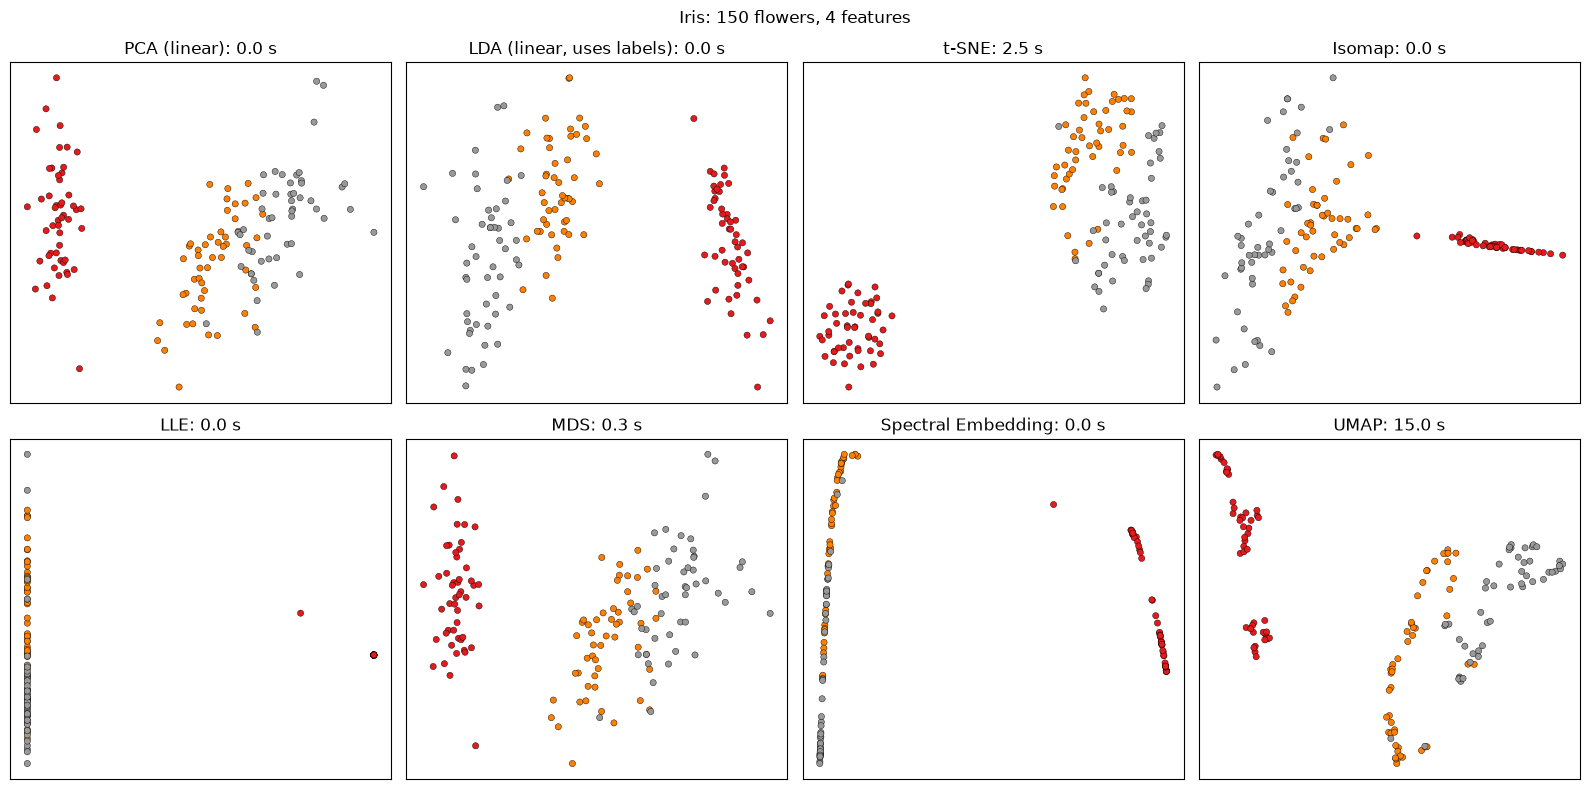

In [2]:
iris = datasets.load_iris()
compare(iris.data, iris.target, "Iris: 150 flowers, 4 features", plt.cm.Set1)

## Digits: 64 dimensions down to 2

This is a harder test. PCA keeps the directions of largest variance, a straight-line projection, and the ten digits overlap.
t-SNE and UMAP keep each digit's nearest neighbours together, and pull most digits into their own islands.
Isomap and Spectral Embedding separate a few digits, LLE collapses, and MDS takes far longer for a muddled result.
UMAP on these digits is the case study at the end of the module.

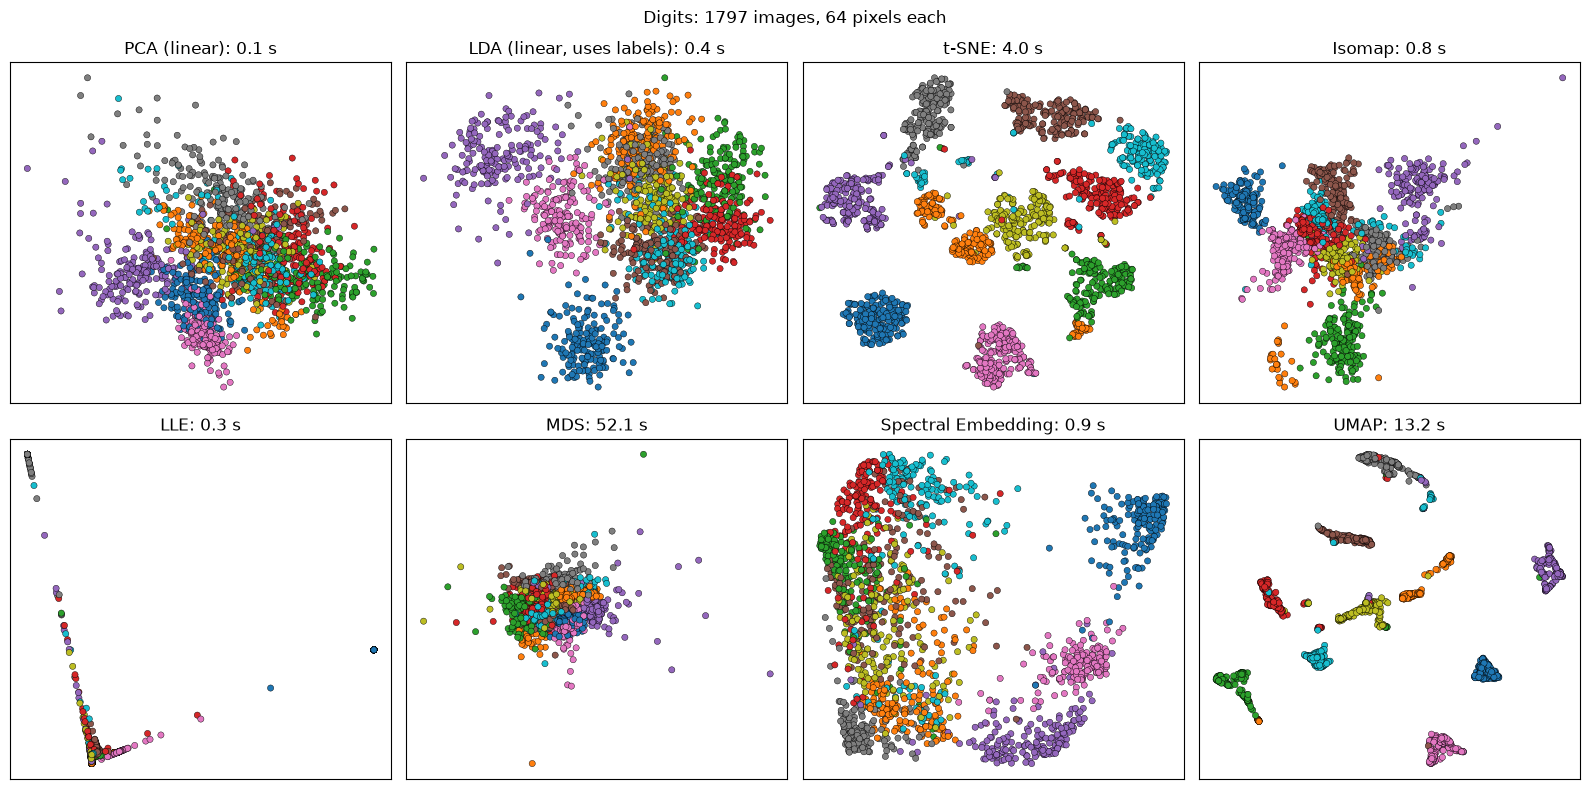

In [3]:
digits = datasets.load_digits()
X, y = digits.data, digits.target
if SMOKE:
    X, y = X[:500], y[:500]
compare(X, y, f"Digits: {len(X)} images, 64 pixels each", plt.cm.tab10)

## Reading these plots

- **Linear (PCA, LDA)** keep straight-line structure, and distances across the whole plot mean something. PCA is fast and repeatable, and a good first look.
- **Non-linear (t-SNE, UMAP, Isomap, LLE, Spectral)** keep neighbourhoods: points close in the plot were close in the original space.
  The size of a cluster and the gap between two clusters in a t-SNE or UMAP plot mean little.
- **MDS** tries to keep every pairwise distance, which gets slow as the data grows (it compares every pair).
- **Check the time** in each title. MDS slows down fastest, since it compares every pair of points.
  On data this small, t-SNE can beat UMAP, whose first run also compiles its code. On large data, UMAP scales better ([McInnes et al., 2018](https://arxiv.org/abs/1802.03426)).

## Try it

- Rerun with a different `random_state` for t-SNE and UMAP. What changes, and what stays?
- Change UMAP's `n_neighbors` (try 5 and 100). Small values show local detail, large values show the global layout.
- Remove the `StandardScaler` step. Which methods change the most on Iris, and why?